# PathSnap — Improved Map-Matching Benchmark (XGBoost + HMM decoding)

**What changed vs. the five-model notebook (≈55% Top-1):**
1. **Preprocessing:** NaN/duplicate-timestamp removal, per-trip UTM projection, outlier-trip detection (trips whose route is mostly >80 m from the GPS track are excluded from *training only*), median imputation inside pipelines.
2. **Richer candidates:** radius 80 m, 16 candidates per point (coverage ≈99.9% on the student split).
3. **Direction-aware features:** GPS heading vs. edge bearing, signed motion along the edge over 3/8/20-point windows (this resolves the two-way-road twin edges that caused most old errors), projection along edge, edge length, node degree, twin flag.
4. **Temporal context:** the same edge's distance in neighbouring GPS points (±1, ±3, ±6) and how persistently it is a candidate.
5. **Models:** Logistic Regression (baseline), Random Forest, **XGBoost** (main). KNN/MLP dropped — they were the weakest and slowest.
6. **HMM/Viterbi decoding** on top of each model's scores: transitions favour staying on the same edge or moving to a connected edge, and penalise jumps and U-turns onto the reverse twin edge. Penalties are tuned on out-of-fold predictions only.

Metric: **Top-1 edge accuracy over all observations** (missing-candidate observations count as wrong). Trip-grouped 3-fold CV; the student split is touched only once at the end.

In [1]:
%pip -q install -U scikit-learn xgboost joblib shapely pyproj

In [2]:
from pathlib import Path
import time, warnings, zipfile, pickle
import numpy as np, pandas as pd
from IPython.display import display
warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    drive.mount("/content/drive"); ROOT = Path("/content/drive/MyDrive/PathSnap")
except ImportError:
    ROOT = Path(".")                       # local run: put the dataset next to the notebook
OUT = ROOT / "improved_results"; OUT.mkdir(parents=True, exist_ok=True)
zp = ROOT / "Student folder.zip"
if zp.exists() and not any(ROOT.rglob("student_test")):
    zipfile.ZipFile(zp).extractall(ROOT)
# robust to nested 'Student folder/Student folder'
TRAIN_DIR = next(p for p in ROOT.rglob("train") if p.is_dir())
TEST_DIR = next(p for p in ROOT.rglob("student_test") if p.is_dir())
print("train:", TRAIN_DIR, "\ntest :", TEST_DIR)

Mounted at /content/drive
train: /content/drive/MyDrive/PathSnap/Student folder/train 
test : /content/drive/MyDrive/PathSnap/Student folder/student_test


## 1. Preprocessing + feature engineering

In [3]:
import shapely
from pyproj import Transformer
from shapely import STRtree

RADIUS, K = 80, 16
OFFS = (-6, -3, -1, 1, 3, 6)

def bearing(dx, dy):
    return np.degrees(np.arctan2(dx, dy)) % 360

def clean_track(track):
    """Preprocessing: drop NaN rows, sort by time, drop duplicate timestamps."""
    t = pd.DataFrame(track, columns=["lon", "lat", "t"]).dropna()
    t = t[(t.lon.abs() <= 180) & (t.lat.abs() <= 90)]
    return t.sort_values("t").drop_duplicates("t").reset_index(drop=True)

def process_trip(split, d, tcode):
    tid = d.name; b = str(d / tid)
    tr = clean_track(np.atleast_2d(np.loadtxt(b + ".track")))
    nodes = np.atleast_2d(np.loadtxt(b + ".nodes"))
    arcs = np.atleast_2d(np.loadtxt(b + ".arcs", dtype=int))
    route = np.loadtxt(b + ".route", dtype=int).reshape(-1)
    lon0, lat0 = np.median(tr[["lon", "lat"]].values, axis=0)
    epsg = (32600 if lat0 >= 0 else 32700) + int((lon0 + 180) // 6) + 1
    T = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
    nx, ny = T.transform(nodes[:, 0], nodes[:, 1])
    A = np.c_[nx[arcs[:, 0]], ny[arcs[:, 0]]]; B = np.c_[nx[arcs[:, 1]], ny[arcs[:, 1]]]
    gx, gy = T.transform(tr.lon.values, tr.lat.values)
    P = np.c_[gx, gy]; n = len(P)
    geoms = shapely.linestrings(np.stack([A, B], axis=1))
    pts = shapely.points(gx, gy)
    # label: nearest ROUTE edge (same definition as original notebook)
    ref = route[STRtree(geoms[route]).nearest(pts)]
    # --- GPS motion features (smoothed heading, speed) ---
    k = 2
    i0 = np.clip(np.arange(n) - k, 0, n - 1); i1 = np.clip(np.arange(n) + k, 0, n - 1)
    dxy = P[i1] - P[i0]; dtt = np.maximum(tr.t.values[i1] - tr.t.values[i0], 1)
    speed = np.hypot(dxy[:, 0], dxy[:, 1]) / dtt
    hdg = bearing(dxy[:, 0], dxy[:, 1])
    gap = np.r_[1, np.diff(tr.t.values)]
    # --- candidates ---
    pi, ei = STRtree(geoms).query(pts, predicate="dwithin", distance=RADIUS)
    dist = shapely.distance(pts[pi], geoms[ei])
    c = pd.DataFrame({"pos": pi, "edge": ei, "dist": dist})
    c = c.sort_values(["pos", "dist", "edge"]); c["rank"] = c.groupby("pos").cumcount() + 1
    c = c[c["rank"] <= K].reset_index(drop=True)
    p, e = c.pos.values, c.edge.values
    ab = B[e] - A[e]; L = np.maximum(np.hypot(ab[:, 0], ab[:, 1]), 1e-6)
    tproj = np.clip(((P[p] - A[e]) * ab).sum(1) / L**2, 0, 1)
    ebr = bearing(ab[:, 0], ab[:, 1])
    ad = np.abs((ebr - hdg[p] + 180) % 360 - 180)
    moving = speed[p] > 1.5
    c["angle"] = np.where(moving, ad, np.nan)
    c["cos_ang"] = np.where(moving, np.cos(np.radians(ad)), np.nan)
    u = ab / L[:, None]
    for w in (3, 8, 20):
        j0 = np.clip(np.arange(n) - w, 0, n - 1); j1 = np.clip(np.arange(n) + w, 0, n - 1)
        dd = (P[j1] - P[j0])[p]; mag = np.hypot(dd[:, 0], dd[:, 1])
        al = (dd * u).sum(1)
        c[f"along{w}"] = al; c[f"cosw{w}"] = al / (mag + 2.0)
    c["speed"] = speed[p]; c["gap"] = gap[p]
    c["edge_len"] = L; c["t_proj"] = tproj
    c["to_start"] = np.hypot(*(P[p] - A[e]).T); c["to_end"] = np.hypot(*(P[p] - B[e]).T)
    # reverse-twin flag and node degree
    ek = arcs[:, 0].astype(np.int64) * len(nodes) + arcs[:, 1]
    rk = arcs[:, 1].astype(np.int64) * len(nodes) + arcs[:, 0]
    c["has_twin"] = np.isin(rk[e], ek).astype(int)
    deg = np.bincount(arcs[:, 0], minlength=len(nodes))
    c["deg_end"] = deg[arcs[e, 1]]; c["deg_start"] = deg[arcs[e, 0]]
    # per-observation relative features
    g = c.groupby("pos")
    c["n_cand"] = g.edge.transform("size"); c["min_dist"] = g.dist.transform("min")
    c["d_from_best"] = c.dist - c.min_dist
    c["d_ratio"] = c.dist / (c.min_dist + 1.0)
    c["d_z"] = (c.dist - g.dist.transform("mean")) / (g.dist.transform("std").fillna(0) + 1.0)
    if c.angle.notna().any():
        c["ang_rank"] = g.angle.rank(method="min")
        c["best_ang_gap"] = c.angle - g.angle.transform("min")
    else:
        c["ang_rank"] = np.nan; c["best_ang_gap"] = np.nan
    # temporal context: same edge's distance in neighbouring observations
    key = c.pos.values.astype(np.int64) * 10_000_000 + e
    order = np.argsort(key); sk = key[order]; sd = c.dist.values[order]
    ctx = []
    for o in OFFS:
        q = (p + o).astype(np.int64) * 10_000_000 + e
        j = np.clip(np.searchsorted(sk, q), 0, len(sk) - 1)
        hit = sk[j] == q
        c[f"d_off{o}"] = np.where(hit, sd[j], np.nan); ctx.append(hit)
    D = c[[f"d_off{o}" for o in OFFS]].values
    c["persist"] = np.sum(ctx, axis=0)
    c["ctx_mean"] = np.nanmean(np.c_[D, c.dist.values], axis=1)
    c["ctx_max"] = np.nanmax(np.c_[D, c.dist.values], axis=1)
    c["ctx_x_best"] = c.ctx_mean - c.groupby("pos").ctx_mean.transform("min")
    c["trip_id"] = tid; c["obs_id"] = tr.t.round().astype(int).astype(str).values[p]
    c["label"] = (e == ref[p]).astype(int); c["split"] = split
    c["tcode"] = tcode
    obs = pd.DataFrame({"trip_id": tid, "pos": np.arange(n), "split": split, "ref": ref,
                        "tcode": tcode, "t": tr.t.values})
    return obs, c, arcs

FEATURES = ["dist", "rank", "n_cand", "min_dist", "d_from_best", "d_ratio", "d_z",
            "angle", "cos_ang", "ang_rank", "best_ang_gap", "speed", "gap",
            "edge_len", "t_proj", "to_start", "to_end", "has_twin", "deg_end", "deg_start",
            "along3", "cosw3", "along8", "cosw8", "along20", "cosw20", "persist", "ctx_mean", "ctx_max", "ctx_x_best"] + [f"d_off{o}" for o in OFFS]

def viterbi(c, arcs, score, w_same=0.0, w_adj=1.0, w_jump=4.0, w_twin=6.0):
    """HMM decoding over one trip. c: candidate frame (pos, edge), score: P(correct)."""
    pos = c.pos.values; e = c.edge.values
    lp = np.log(np.clip(score, 1e-6, 1 - 1e-6))
    starts = np.r_[0, np.flatnonzero(np.diff(pos)) + 1, len(pos)]
    prev_lp = None; back = []; spans = []
    for a, b in zip(starts[:-1], starts[1:]):
        ee = e[a:b]; cur = lp[a:b]
        if prev_lp is None:
            tot = cur
        else:
            pe = prev_e
            same = ee[None, :] == pe[:, None]
            adj = arcs[pe, 1][:, None] == arcs[ee, 0][None, :]
            twin = (arcs[pe, 0][:, None] == arcs[ee, 1][None, :]) & (arcs[pe, 1][:, None] == arcs[ee, 0][None, :])
            pen = np.where(same, w_same, np.where(twin, w_twin, np.where(adj, w_adj, w_jump)))
            m = prev_lp[:, None] - pen
            bi = m.argmax(0); tot = cur + m[bi, np.arange(len(ee))]
            back.append(bi)
        spans.append((a, b)); prev_lp = tot; prev_e = ee; last = tot
        if prev_lp is not None and len(back) == 0: pass
    # backtrack
    out = np.empty(len(spans), dtype=int); idx = int(np.argmax(prev_lp))
    chosen = np.empty(len(spans), dtype=np.int64)
    for s in range(len(spans) - 1, -1, -1):
        a, b = spans[s]; chosen[s] = e[a + idx]
        if s > 0: idx = back[s - 1][idx]
    return pos[[a for a, _ in spans]], chosen


## 2. Build the dataset and quality-check it

In [4]:
O, Cd, ARCS = [], [], {}
t0, code_ = time.time(), 0
for split, d in [("train", TRAIN_DIR), ("student", TEST_DIR)]:
    for trip in sorted(p for p in d.iterdir() if p.is_dir()):
        o, c, a = process_trip(split, trip, code_)
        O.append(o); Cd.append(c); ARCS[code_] = a; code_ += 1
obs = pd.concat(O, ignore_index=True); cand = pd.concat(Cd, ignore_index=True)
cand[FEATURES] = cand[FEATURES].astype("float32")   # halve memory
print(f"Built in {time.time()-t0:.0f}s: {len(obs):,} observations, {len(cand):,} candidate rows")

hit = cand.groupby(["tcode", "pos"]).label.max().reset_index()
obs = obs.merge(hit.rename(columns={"label": "covered"}), on=["tcode", "pos"], how="left").fillna({"covered": 0})
trip_cov = obs.groupby(["tcode", "trip_id", "split"]).covered.mean().reset_index()
print("Candidate coverage by split (ceiling for Top-1 accuracy):")
display(obs.groupby("split").covered.mean().to_frame("coverage").round(4))
outliers = set(trip_cov[(trip_cov.split == "train") & (trip_cov.covered < 0.5)].tcode)
print("Outlier training trips excluded from fitting/CV:", trip_cov[trip_cov.tcode.isin(outliers)][["trip_id", "covered"]].values.tolist())

Built in 168s: 227,577 observations, 2,229,735 candidate rows
Candidate coverage by split (ceiling for Top-1 accuracy):


,coverage
split,
student,0.9992
train,0.8939


Outlier training trips excluded from fitting/CV: [['00000033', 0.3417180013689254], ['00000054', 0.12354372702324859]]


## 3. Models, evaluation and HMM decoding

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from xgboost import XGBClassifier
import joblib

def make_models():
    return {
        "Logistic Regression": Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
            ("sc", StandardScaler()), ("m", LogisticRegression(C=1.0, max_iter=1000))]),
        "Random Forest": Pipeline([("imp", SimpleImputer(strategy="median")),
            ("m", RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=5, max_samples=0.3,
                  max_features="sqrt", n_jobs=-1, random_state=42))]),
        "XGBoost": XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.8,
                  colsample_bytree=0.8, min_child_weight=3, reg_lambda=2, tree_method="hist",
                  n_jobs=-1, random_state=42),   # handles NaN natively
    }

def positives_only(df):  # train only on points whose true edge is among the candidates
    return df[df.groupby(["tcode", "pos"]).label.transform("max") == 1]

def evaluate(frame, obs_sub, score, **hmm):
    """Top-1 over ALL observations, before (raw) and after Viterbi decoding."""
    f = frame.assign(score=score)
    raw = f.loc[f.groupby(["tcode", "pos"]).score.idxmax()].label.sum() / len(obs_sub)
    hits = 0
    for tc, g in f.groupby("tcode"):
        g = g.sort_values(["pos", "rank"])
        pp, ch = viterbi(g, ARCS[tc], g.score.values, **hmm)
        ref = obs_sub[obs_sub.tcode == tc].set_index("pos").ref
        hits += (ref.reindex(pp).values == ch).sum()
    return raw, hits / len(obs_sub)

tr_codes = np.array(sorted(set(obs[obs.split == "train"].tcode) - outliers))
trc = cand[cand.tcode.isin(tr_codes)]; tro = obs[obs.tcode.isin(tr_codes)]
folds = list(GroupKFold(3).split(tr_codes, groups=tr_codes))
oof = {n: np.zeros(len(trc)) for n in make_models()}
for k, (a, b) in enumerate(folds, 1):
    fit = positives_only(trc[trc.tcode.isin(tr_codes[a])])
    msk = trc.tcode.isin(tr_codes[b]).values
    for name, m in make_models().items():
        t0 = time.time(); m.fit(fit[FEATURES], fit.label)
        oof[name][msk] = m.predict_proba(trc[msk][FEATURES])[:, 1]
        print(f"fold {k} {name:20s} {time.time()-t0:5.0f}s")

fold 1 Logistic Regression     39s
fold 1 Random Forest          253s
fold 1 XGBoost                 49s
fold 2 Logistic Regression     36s
fold 2 Random Forest          264s
fold 2 XGBoost                 49s
fold 3 Logistic Regression     37s
fold 3 Random Forest          270s
fold 3 XGBoost                 50s


### HMM penalty tuning (out-of-fold scores only)

In [6]:
GRID = [dict(w_adj=1, w_jump=4, w_twin=6), dict(w_adj=2, w_jump=8, w_twin=14), dict(w_adj=3, w_jump=10, w_twin=20)]
rows, best_hmm = [], {}
for name in oof:
    res = [(evaluate(trc, tro, oof[name], **g), g) for g in GRID]
    (raw, vit), g = max(res, key=lambda r: r[0][1]); best_hmm[name] = g
    rows.append({"model": name, "CV Top-1 raw": raw, "CV Top-1 + HMM": vit, "HMM params": str(g)})
cv_table = pd.DataFrame(rows).sort_values("CV Top-1 + HMM", ascending=False)
display(cv_table.round(4))

,model,CV Top-1 raw,CV Top-1 + HMM,HMM params
2,XGBoost,0.8942,0.8953,"{'w_adj': 3, 'w_jump': 10, 'w_twin': 20}"
1,Random Forest,0.8895,0.8939,"{'w_adj': 1, 'w_jump': 4, 'w_twin': 6}"
0,Logistic Regression,0.8868,0.8879,"{'w_adj': 3, 'w_jump': 10, 'w_twin': 20}"


## 4. Final fit on all training trips → student split

In [7]:
st = cand[cand.split == "student"]; so = obs[obs.split == "student"]
fit = positives_only(trc); out, final = [], {}
for name, m in make_models().items():
    m.fit(fit[FEATURES], fit.label); final[name] = m
    raw, vit = evaluate(st, so, m.predict_proba(st[FEATURES])[:, 1], **best_hmm[name])
    out.append({"model": name, "Student Top-1 raw": raw, "Student Top-1 + HMM": vit})
    joblib.dump(m, OUT / (name.lower().replace(" ", "_") + ".joblib"))
student_table = pd.DataFrame(out)
final_table = cv_table.merge(student_table, on="model").sort_values("Student Top-1 + HMM", ascending=False)
display(final_table.round(4))
print(f"Student candidate coverage (accuracy ceiling): {so.covered.mean():.2%}")
final_table.to_csv(OUT / "model_comparison.csv", index=False)

,model,CV Top-1 raw,CV Top-1 + HMM,HMM params,Student Top-1 raw,Student Top-1 + HMM
0,XGBoost,0.8942,0.8953,"{'w_adj': 3, 'w_jump': 10, 'w_twin': 20}",0.8890,0.9018
1,Random Forest,0.8895,0.8939,"{'w_adj': 1, 'w_jump': 4, 'w_twin': 6}",0.8780,0.8957
2,Logistic Regression,0.8868,0.8879,"{'w_adj': 3, 'w_jump': 10, 'w_twin': 20}",0.8646,0.8560


Student candidate coverage (accuracy ceiling): 99.92%


## 5. What drives the predictions?

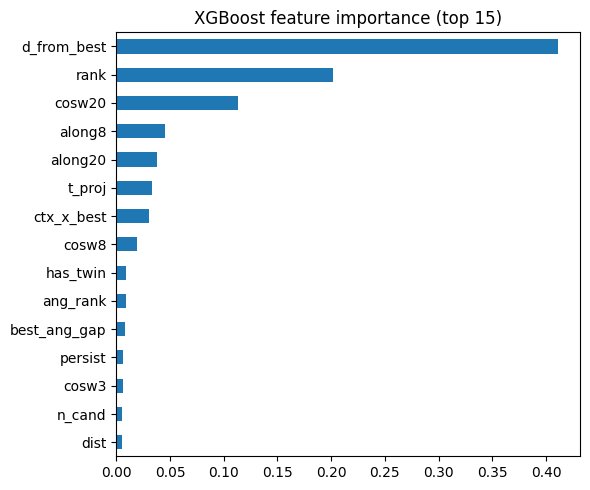

Best: XGBoost | CV Top-1 89.53% | Student Top-1 90.18%


In [8]:
import matplotlib.pyplot as plt
imp = pd.Series(final["XGBoost"].feature_importances_, FEATURES).sort_values().tail(15)
imp.plot.barh(figsize=(6, 5), title="XGBoost feature importance (top 15)"); plt.tight_layout(); plt.show()
best = final_table.iloc[0]
print(f"Best: {best.model} | CV Top-1 {best['CV Top-1 + HMM']:.2%} | Student Top-1 {best['Student Top-1 + HMM']:.2%}")